In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

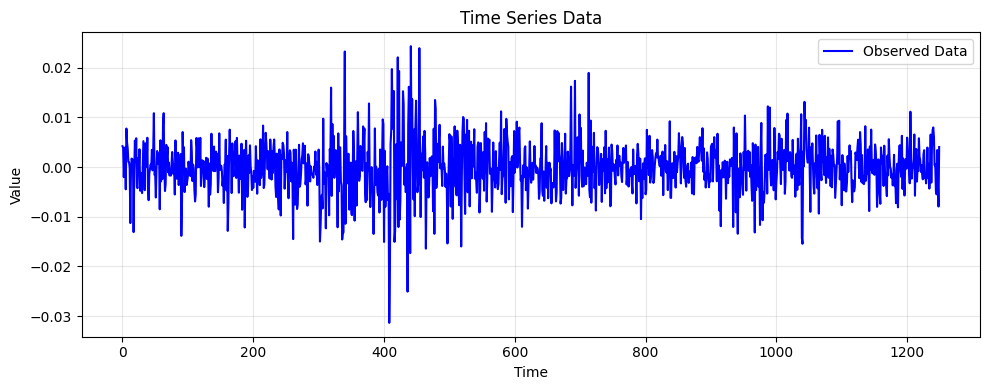

In [3]:
y = pd.read_csv('data.csv', header=None)
data_array = y.values.flatten()

plt.figure(figsize=(10, 4))
plt.plot(data_array, label='Observed Data', color='blue')
plt.title('Time Series Data')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
import numpy as np
from scipy.stats import invgamma

# ============================================================
# 1. Prior
# sigma2 ~ IG(1,1)
# beta2  ~ IG(1,1)
# rho    ~ Uniform(-1,1)
# ============================================================
def log_prior(sigma2, beta2, rho):
    if sigma2 <= 0 or beta2 <= 0 or not (-1 < rho < 1):
        return -np.inf

    lp_sigma = invgamma.logpdf(sigma2, a=1.0, scale=1.0)
    lp_beta  = invgamma.logpdf(beta2,  a=1.0, scale=1.0)
    lp_rho   = -np.log(2.0)

    return lp_sigma + lp_beta + lp_rho


# ============================================================
# 2. Systematic resampling
# ============================================================
def systematic_resampling(weights, rng):
    N = len(weights)
    positions = (rng.random() + np.arange(N)) / N
    idx = np.zeros(N, dtype=int)

    cumsum = np.cumsum(weights)
    i, j = 0, 0
    while i < N:
        if positions[i] < cumsum[j]:
            idx[i] = j
            i += 1
        else:
            j += 1
    return idx


# ============================================================
# 3. Conditional Particle Filter
# Model:
#   x0 ~ N(0, sigma2 / (1-rho^2))
#   x_t | x_{t-1} ~ N(rho x_{t-1}, sigma2)
#   y_t | x_t ~ N(0, beta2 * exp(x_t))
# One particle is forced to follow x_ref
# ============================================================
def conditional_particle_filter(y, x_ref, sigma2, beta2, rho, N=200, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    T = len(y)
    eps = 1e-12

    particles = np.zeros((N, T))
    ancestors = np.zeros((N, T), dtype=int)
    weights   = np.zeros((N, T))

    # -------------------------
    # t = 0
    # -------------------------
    x0_var = sigma2 / max(1.0 - rho**2, eps)

    # first N-1 particles sampled normally
    particles[:N-1, 0] = rng.normal(0.0, np.sqrt(x0_var), size=N-1)

    # last particle fixed to reference path
    particles[N-1, 0] = x_ref[0]

    var0 = beta2 * np.exp(particles[:, 0])
    logw0 = -0.5 * np.log(2.0 * np.pi * var0) - 0.5 * (y[0] ** 2) / var0
    maxlw0 = np.max(logw0)
    weights[:, 0] = np.exp(logw0 - maxlw0)
    weights[:, 0] /= np.sum(weights[:, 0])

    # -------------------------
    # t = 1,...,T-1
    # -------------------------
    for t in range(1, T):
        parent_idx = systematic_resampling(weights[:, t - 1], rng)

        # first N-1 particles evolve freely
        for i in range(N - 1):
            parent = parent_idx[i]
            ancestors[i, t] = parent
            particles[i, t] = (
                rho * particles[parent, t - 1]
                + rng.normal(0.0, np.sqrt(sigma2))
            )

        # last particle fixed to reference path
        particles[N - 1, t] = x_ref[t]

        # choose an ancestor for the fixed particle
        ref_parent = rng.choice(N, p=weights[:, t - 1])
        ancestors[N - 1, t] = ref_parent

        # observation weights
        var_t = beta2 * np.exp(particles[:, t])
        logw = -0.5 * np.log(2.0 * np.pi * var_t) - 0.5 * (y[t] ** 2) / var_t
        maxlw = np.max(logw)
        weights[:, t] = np.exp(logw - maxlw)
        weights[:, t] /= np.sum(weights[:, t])

    return particles, ancestors, weights


# ============================================================
# 4. Backward sampling of a whole latent trajectory
# ============================================================
def backward_sample_trajectory(particles, ancestors, weights, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    N, T = particles.shape
    x_new = np.zeros(T)

    # sample terminal particle
    b = rng.choice(N, p=weights[:, -1])
    x_new[-1] = particles[b, -1]

    # trace back ancestors
    for t in range(T - 1, 0, -1):
        b = ancestors[b, t]
        x_new[t - 1] = particles[b, t - 1]

    return x_new


# ============================================================
# 5. Particle Gibbs update for latent path x
# ============================================================
def particle_gibbs_update(y, x_prev, sigma2, beta2, rho, N=200, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    particles, ancestors, weights = conditional_particle_filter(
        y=y,
        x_ref=x_prev,
        sigma2=sigma2,
        beta2=beta2,
        rho=rho,
        N=N,
        rng=rng
    )

    x_new = backward_sample_trajectory(particles, ancestors, weights, rng)
    return x_new


# ============================================================
# 6. Particle Gibbs MCMC
# Step 1: x | theta, y      via conditional PF
# Step 2: sigma2 | x, rho   via MH on log scale
# Step 3: beta2  | x, y     via MH on log scale
# Step 4: rho    | x, sigma2 via RW-MH
# ============================================================
def particle_gibbs_mcmc(
    y,
    sigma2_init=0.2,
    beta2_init=0.2,
    rho_init=0.95,
    n_iter=3000,
    N_particles=200,
    step_sigma=0.08,
    step_beta=0.08,
    step_rho=0.02,
    rng=None
):
    if rng is None:
        rng = np.random.default_rng()

    T = len(y)

    # storage
    sigma2_path = np.zeros(n_iter)
    beta2_path  = np.zeros(n_iter)
    rho_path    = np.zeros(n_iter)
    x_path      = np.zeros((n_iter, T))

    acc_sigma = np.zeros(n_iter, dtype=bool)
    acc_beta  = np.zeros(n_iter, dtype=bool)
    acc_rho   = np.zeros(n_iter, dtype=bool)

    # init
    sigma2 = sigma2_init
    beta2  = beta2_init
    rho    = rho_init
    x      = rng.normal(0.0, 0.1, size=T)

    sigma2_path[0] = sigma2
    beta2_path[0]  = beta2
    rho_path[0]    = rho
    x_path[0]      = x

    for it in range(1, n_iter):
        # ------------------------------------------------
        # Step 1: sample latent path x | sigma2, beta2, rho, y
        # ------------------------------------------------
        x = particle_gibbs_update(
            y=y,
            x_prev=x,
            sigma2=sigma2,
            beta2=beta2,
            rho=rho,
            N=N_particles,
            rng=rng
        )

        # ------------------------------------------------
        # Step 2: update sigma2 | x, rho
        # x_t = rho x_{t-1} + N(0, sigma2)
        # ------------------------------------------------
        log_s_old = np.log(sigma2)
        log_s_new = log_s_old + rng.normal(0.0, step_sigma)
        s_new = np.exp(log_s_new)

        x_innov = x[1:] - rho * x[:-1]

        ll_old = -0.5 * np.sum(x_innov**2 / sigma2) - 0.5 * (T - 1) * np.log(sigma2)
        ll_new = -0.5 * np.sum(x_innov**2 / s_new)  - 0.5 * (T - 1) * np.log(s_new)

        lp_old = invgamma.logpdf(sigma2, a=1.0, scale=1.0)
        lp_new = invgamma.logpdf(s_new,  a=1.0, scale=1.0)

        log_alpha_sigma = (ll_new + lp_new) - (ll_old + lp_old) + (log_s_new - log_s_old)

        if np.log(rng.uniform()) < min(0.0, log_alpha_sigma):
            sigma2 = s_new
            acc_sigma[it] = True

        # ------------------------------------------------
        # Step 3: update beta2 | x, y
        # y_t | x_t ~ N(0, beta2 exp(x_t))
        # ------------------------------------------------
        log_b_old = np.log(beta2)
        log_b_new = log_b_old + rng.normal(0.0, step_beta)
        b_new = np.exp(log_b_new)

        var_old = beta2 * np.exp(x)
        var_new = b_new  * np.exp(x)

        ll_old = -0.5 * np.sum(np.log(2.0 * np.pi * var_old) + y**2 / var_old)
        ll_new = -0.5 * np.sum(np.log(2.0 * np.pi * var_new) + y**2 / var_new)

        lp_old = invgamma.logpdf(beta2, a=1.0, scale=1.0)
        lp_new = invgamma.logpdf(b_new,  a=1.0, scale=1.0)

        log_alpha_beta = (ll_new + lp_new) - (ll_old + lp_old) + (log_b_new - log_b_old)

        if np.log(rng.uniform()) < min(0.0, log_alpha_beta):
            beta2 = b_new
            acc_beta[it] = True

        # ------------------------------------------------
        # Step 4: update rho | x, sigma2
        # RW-MH on original scale
        # ------------------------------------------------
        r_new = rho + rng.normal(0.0, step_rho)

        if -0.999 < r_new < 0.999:
            x_dep = x[:-1]
            x_tar = x[1:]

            ll_old = -0.5 * np.sum((x_tar - rho   * x_dep)**2 / sigma2)
            ll_new = -0.5 * np.sum((x_tar - r_new * x_dep)**2 / sigma2)

            # uniform prior on (-1,1)
            log_alpha_rho = ll_new - ll_old

            if np.log(rng.uniform()) < min(0.0, log_alpha_rho):
                rho = r_new
                acc_rho[it] = True

        # save
        sigma2_path[it] = sigma2
        beta2_path[it]  = beta2
        rho_path[it]    = rho
        x_path[it]      = x

    return {
        "x_path": x_path,
        "sigma2_path": sigma2_path,
        "beta2_path": beta2_path,
        "rho_path": rho_path,
        "accept_sigma": np.mean(acc_sigma),
        "accept_beta": np.mean(acc_beta),
        "accept_rho": np.mean(acc_rho),
    }

In [5]:
rng = np.random.default_rng(123)

out = particle_gibbs_mcmc(
    data_array[:1000],
    sigma2_init=0.2,
    beta2_init=0.2,
    rho_init=0.95,
    n_iter=3000,
    N_particles=200,
    step_sigma=0.08,
    step_beta=0.08,
    step_rho=0.001,
    rng=rng
)

sigma2_path = out["sigma2_path"]
beta2_path  = out["beta2_path"]
rho_path    = out["rho_path"]
x_path      = out["x_path"]

print("accept sigma2 =", out["accept_sigma"])
print("accept beta2  =", out["accept_beta"])
print("accept rho    =", out["accept_rho"])

accept sigma2 = 0.5386666666666666
accept beta2  = 0.5496666666666666
accept rho    = 0.501


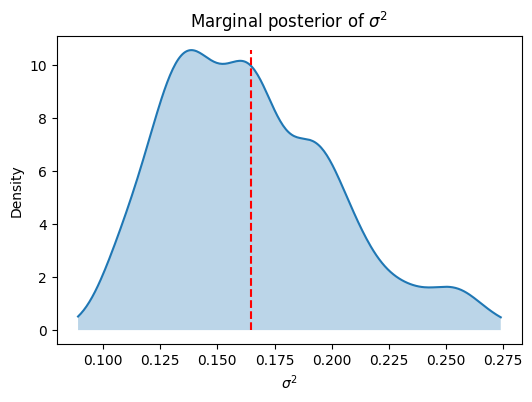

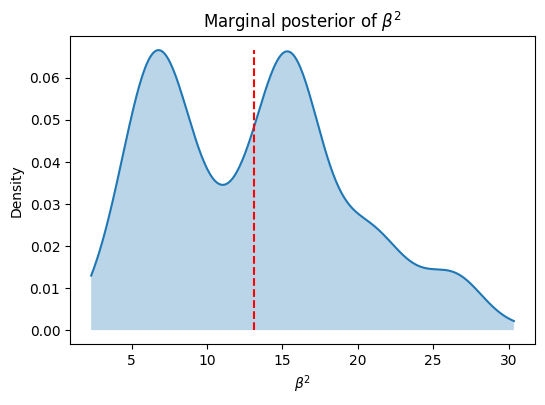

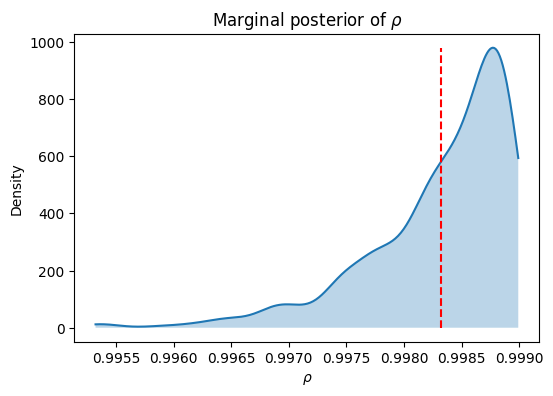

In [6]:
from scipy.stats import gaussian_kde

burn_in = 2000

sigma2_post = sigma2_path[burn_in:]
beta2_post = beta2_path[burn_in:]
rho_post = rho_path[burn_in:]

# sigma^2
x_sigma = np.linspace(np.min(sigma2_post), np.max(sigma2_post), 300)
kde_sigma = gaussian_kde(sigma2_post)
y_sigma = kde_sigma(x_sigma)

plt.figure(figsize=(6,4))
plt.plot(x_sigma, y_sigma)
plt.vlines(np.mean(sigma2_post), 0, np.max(y_sigma), color='red', linestyle='--', label='Posterior Mean')
plt.fill_between(x_sigma, y_sigma, alpha=0.3)
plt.xlabel(r'$\sigma^2$')
plt.ylabel('Density')
plt.title(r'Marginal posterior of $\sigma^2$')
plt.show()

# beta^2
x_beta = np.linspace(np.min(beta2_post), np.max(beta2_post), 300)
kde_beta = gaussian_kde(beta2_post)
y_beta = kde_beta(x_beta)

plt.figure(figsize=(6,4))
plt.plot(x_beta, y_beta)
plt.vlines(np.mean(beta2_post), 0, np.max(y_beta), color='red', linestyle='--', label='Posterior Mean')
plt.fill_between(x_beta, y_beta, alpha=0.3)
plt.xlabel(r'$\beta^2$')
plt.ylabel('Density')
plt.title(r'Marginal posterior of $\beta^2$')
plt.show()

# rho
x_rho = np.linspace(np.min(rho_post), np.max(rho_post), 300)
kde_rho = gaussian_kde(rho_post)
y_rho = kde_rho(x_rho)

plt.figure(figsize=(6,4))
plt.plot(x_rho, y_rho)
plt.vlines(np.mean(rho_post), 0, np.max(y_rho), color='red', linestyle='--', label='Posterior Mean')
plt.fill_between(x_rho, y_rho, alpha=0.3)
plt.xlabel(r'$\rho$')
plt.ylabel('Density')
plt.title(r'Marginal posterior of $\rho$')
plt.show()

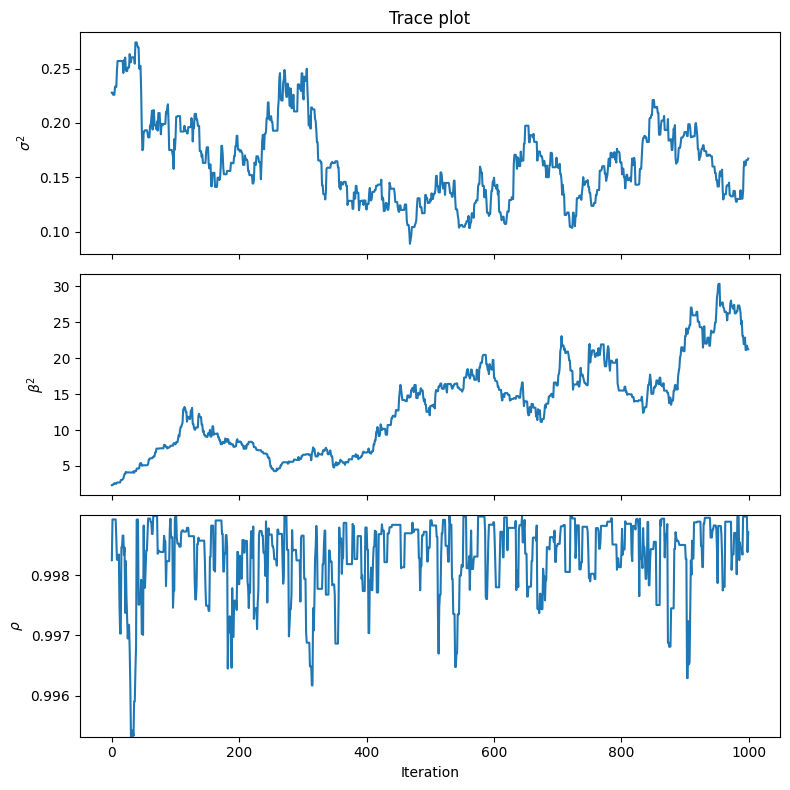

In [7]:
def trace_plot(sigma2_path, beta2_path, rho_path):
    fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)

    axes[0].plot(sigma2_path)
    axes[0].set_ylabel(r'$\sigma^2$')
    axes[0].set_title('Trace plot')

    axes[1].plot(beta2_path)
    axes[1].set_ylabel(r'$\beta^2$')

    axes[2].plot(rho_path)
    axes[2].set_ylim(np.min(rho_post), np.max(rho_post))
    axes[2].set_ylabel(r'$\rho$')
    axes[2].set_xlabel('Iteration')

    plt.tight_layout()
    plt.show()

trace_plot(sigma2_post, beta2_post, rho_post)

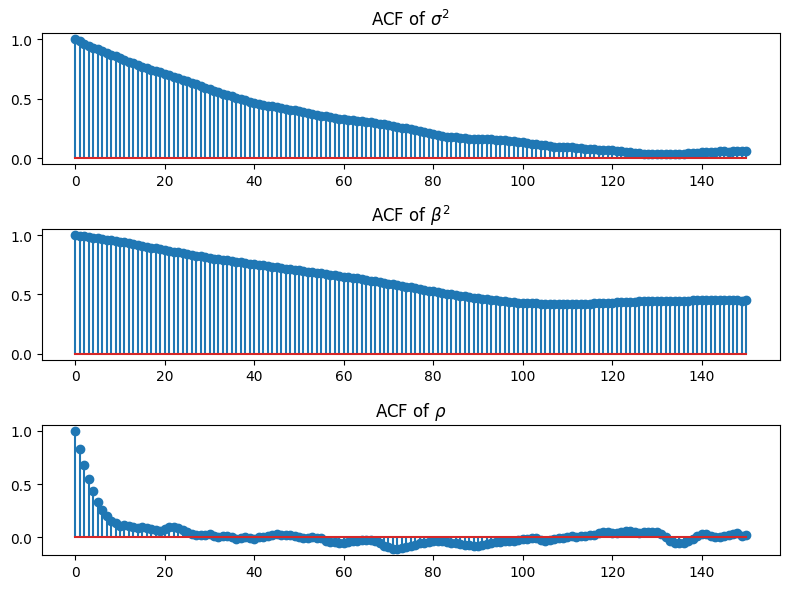

In [250]:
def acf(x, max_lag=50):
    x = np.asarray(x)
    x = x - np.mean(x)
    n = len(x)

    var = np.dot(x, x) / n
    vals = [1.0]

    for lag in range(1, max_lag + 1):
        val = np.dot(x[:-lag], x[lag:]) / ((n - lag) * var)
        vals.append(val)

    return np.array(vals)

acf_sigma2 = acf(sigma2_post, max_lag=150)
acf_beta2 = acf(beta2_post, max_lag=150)
acf_rho = acf(rho_post, max_lag=150)

plt.figure(figsize=(8, 6))
plt.subplot(3, 1, 1)
plt.stem(range(len(acf_sigma2)), acf_sigma2)
plt.title(r'ACF of $\sigma^2$')
plt.subplot(3, 1, 2)
plt.stem(range(len(acf_beta2)), acf_beta2)
plt.title(r'ACF of $\beta^2$')
plt.subplot(3, 1, 3)
plt.stem(range(len(acf_rho)), acf_rho)
plt.title(r'ACF of $\rho$')
plt.tight_layout()
plt.show()

In [8]:
def predictive_simulation_sv(
    sigma2_post, beta2_post, rho_post, x_path_post, H=20, rng=rng
):


    M = len(sigma2_post)
    y_future_samples = np.zeros((M, H))
    x_future_samples = np.zeros((M, H))

    for m in range(M):
        sigma2 = sigma2_post[m]
        beta2  = beta2_post[m]
        rho    = rho_post[m]

        x_curr = x_path_post[m, -1]

        for h in range(H):
            # simulate future latent state
            x_next = rho * x_curr + np.sqrt(sigma2) * rng.normal()
            x_future_samples[m, h] = x_next

            # simulate future observation
            y_next = np.sqrt(beta2 * np.exp(x_next)) * rng.normal()
            y_future_samples[m, h] = y_next

            # move forward
            x_curr = x_next

    return y_future_samples, x_future_samples


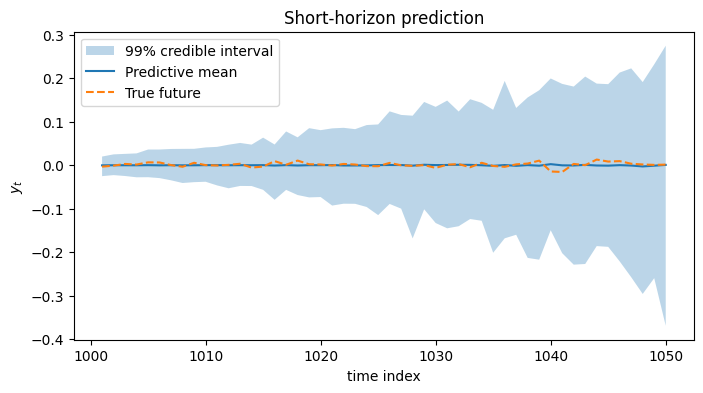

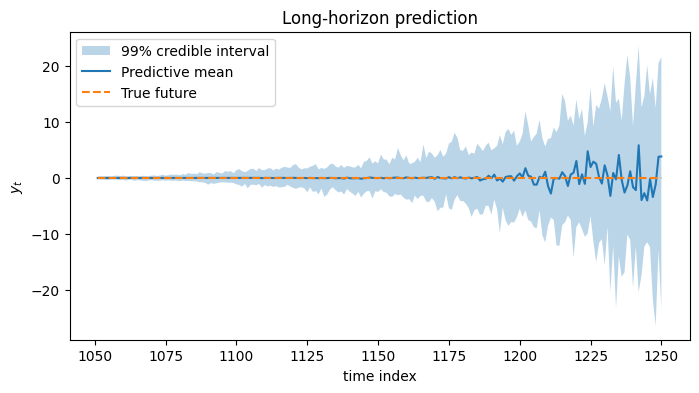

In [11]:
burn_in = 500
T = 1000

sigma2_post = sigma2_path[burn_in:]
beta2_post  = beta2_path[burn_in:]
rho_post    = rho_path[burn_in:]
x_post      = x_path[burn_in:, :]   # shape (M, T+1)

H = 250
y_future_samples, x_future_samples = predictive_simulation_sv(
    sigma2_post, beta2_post, rho_post, x_post, H=H
)

pred_mean = y_future_samples.mean(axis=0)
lower = np.quantile(y_future_samples, 0.005, axis=0)
upper = np.quantile(y_future_samples, 0.995, axis=0)

y_true_future = y[T:len(data_array)]
n_grid = np.arange(T + 1, len(data_array) + 1)

split = 50   

# --- short horizon ---
plt.figure(figsize=(8,4))
plt.fill_between(n_grid[:split], lower[:split], upper[:split], alpha=0.3, label='99% credible interval')
plt.plot(n_grid[:split], pred_mean[:split], label='Predictive mean')
plt.plot(n_grid[:split], y_true_future[:split], '--', label='True future')
plt.xlabel('time index')
plt.ylabel(r'$y_t$')
plt.title('Short-horizon prediction')
plt.legend()
plt.show()

# --- long horizon ---
plt.figure(figsize=(8,4))
plt.fill_between(n_grid[split:], lower[split:], upper[split:], alpha=0.3, label='99% credible interval')
plt.plot(n_grid[split:], pred_mean[split:], label='Predictive mean')
plt.plot(n_grid[split:], y_true_future[split:], '--', label='True future')
plt.xlabel('time index')
plt.ylabel(r'$y_t$')
plt.title('Long-horizon prediction')
plt.legend()
plt.show()